# 🎯 Lesson 7: Evaluating Classification Models
**Week 6 · Notebook 7 of 10 · ⏱️ about 120 minutes**

---

## 🎯 Learning objectives
By the end of this lesson you will be able to:

1. **Explain the accuracy paradox**: why 85% accuracy can mean a useless model.
2. **Build and read a confusion matrix** (TP, FP, FN, TN).
3. **Compute and interpret** accuracy, precision, recall, specificity and F1.
4. **Move the decision threshold** to trade precision against recall, and pick it using costs.
5. **Draw and interpret ROC and precision-recall curves**, and explain what AUC means.
6. **Choose** the right metric for a real-world problem.

## 🗺️ Roadmap
`Accuracy and its paradox` → `Confusion matrix` → `Precision / Recall / F1` → `Thresholds` → `ROC & AUC` → `Multiclass` → **Problems**

In [1]:
import sys
sys.path.append("..")
from course_utils import *
setup()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report, roc_curve, roc_auc_score,
                             precision_recall_curve, average_precision_score)

---
# 📖 Part 1: Accuracy… and why it can lie

**Accuracy** = (correct predictions) ÷ (all predictions). It's the first metric everyone reaches for, because it's intuitive.

Let's put it to the test. We'll predict **customer churn** (will a customer cancel?). Only about **15%** of customers churn.

In [2]:
churn = load("churn.csv")
X, y = churn.drop(columns="churned"), churn["churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

print(f"share of churners: {y.mean():.1%}")

# A "model" that never learns anything: it always predicts the most common class ("stays").
lazy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"\nThe lazy model's accuracy on the test set: {accuracy_score(y_test, lazy.predict(X_test)):.1%}")
print(f"Churners it catches                        : {recall_score(y_test, lazy.predict(X_test)):.0%}")

share of churners: 15.2%

The lazy model's accuracy on the test set: 84.8%
Churners it catches                        : 0%


**85% accurate, and completely useless.** It never identifies a single customer who is about to leave, which was the *entire point*.

This is the **accuracy paradox**: when classes are imbalanced, a trivial model can score high accuracy. The same happens in fraud (0.1% fraud), disease screening (1% sick), and defect detection. **Accuracy is only meaningful when classes are roughly balanced and all mistakes cost the same.** We need sharper tools.

---
# 📖 Part 2: The confusion matrix

A classifier can be right or wrong in **two different ways**. The confusion matrix counts all four outcomes. We call the class we're hunting for the **positive** class (here: *churn = 1*, *disease present*, *spam*, *fraud*).

| | **Predicted positive** | **Predicted negative** |
|---|---|---|
| **Actually positive** | ✅ **TP**: True Positive (caught it!) | ❌ **FN**: False Negative (missed it; "Type II error") |
| **Actually negative** | ❌ **FP**: False Positive (false alarm; "Type I error") | ✅ **TN**: True Negative (correctly ignored) |

> 🧠 **Memory trick.** The *second* word is the **prediction** (positive/negative). The *first* word says if the prediction was **true** (right) or **false** (wrong). *False Negative* = predicted negative, and that was wrong.

### 🧑‍🏫 Worked Example 1: A hospital screening test, by hand

Ten patients. `1` = has the disease. The test's results:

| Patient | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| **Truth** | 1 | 1 | 1 | 1 | 0 | 0 | 0 | 0 | 0 | 0 |
| **Test says** | 1 | 1 | 1 | 0 | 1 | 1 | 0 | 0 | 0 | 0 |

*Tally:* patients 1–3 are sick and flagged → **TP = 3**. Patient 4 is sick but missed → **FN = 1**. Patients 5–6 are healthy but flagged → **FP = 2**. Patients 7–10 are healthy and cleared → **TN = 4**. (3 + 1 + 2 + 4 = 10 ✔)

Now the metrics, each answering a different question:

| Metric | Formula | Here | The question it answers |
|---|---|---|---|
| **Accuracy** | (TP+TN) ÷ all | 7/10 = **0.70** | How often is the model right overall? |
| **Precision** | TP ÷ (TP+FP) | 3/5 = **0.60** | When it says *positive*, how often is it **right**? |
| **Recall** (sensitivity, TPR) | TP ÷ (TP+FN) | 3/4 = **0.75** | Of all the *actual positives*, how many did it **find**? |
| **Specificity** (TNR) | TN ÷ (TN+FP) | 4/6 = **0.67** | Of all actual negatives, how many did it correctly clear? |
| **F1-score** | 2·P·R ÷ (P+R) | 2·0.6·0.75 ÷ 1.35 = **0.667** | One number balancing precision and recall |

TP=3  FN=1  FP=2  TN=4

accuracy  = 0.700
precision = 0.600
recall    = 0.750
F1        = 0.667


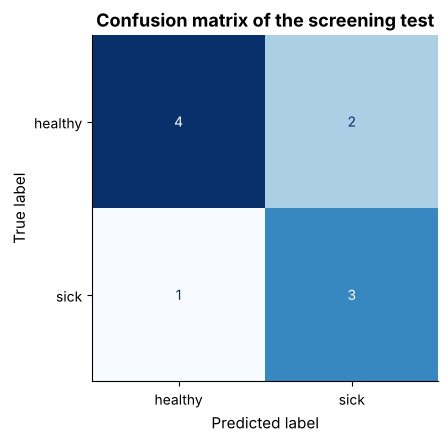

In [3]:
y_true = np.array([1, 1, 1, 1, 0, 0, 0, 0, 0, 0])
y_pred = np.array([1, 1, 1, 0, 1, 1, 0, 0, 0, 0])

cm = confusion_matrix(y_true, y_pred)
tn, fp, fn, tp = cm.ravel()                     # sklearn's layout: [[TN, FP], [FN, TP]]
print(f"TP={tp}  FN={fn}  FP={fp}  TN={tn}\n")
print(f"accuracy  = {accuracy_score(y_true, y_pred):.3f}")
print(f"precision = {precision_score(y_true, y_pred):.3f}")
print(f"recall    = {recall_score(y_true, y_pred):.3f}")
print(f"F1        = {f1_score(y_true, y_pred):.3f}")
ConfusionMatrixDisplay(cm, display_labels=["healthy", "sick"]).plot(cmap="Blues", colorbar=False)
plt.grid(False); plt.title("Confusion matrix of the screening test"); plt.show()

> ⚠️ **scikit-learn's layout:** rows are the *actual* classes, columns the *predicted* ones, and the order is `[[TN, FP], [FN, TP]]`. (Other textbooks flip it. Always check which axis is which!)

### Precision vs. recall: a smoke-alarm analogy 🔥

* **High precision** = *when the alarm rings, there's really a fire.* (Few false alarms. You trust it.)
* **High recall** = *every real fire sets off the alarm.* (Few missed fires. You're safe.)

You can get **perfect recall by ringing the alarm all the time** (never miss a fire (but constant false alarms), and **perfect precision by ringing it only once, when the building is visibly ablaze** (every ring is real) but you miss most fires). The two pull against each other.

### Which error is worse? It depends on the problem.

| Application | Worse mistake | So prioritise… |
|---|---|---|
| **Cancer screening** | FN (missing a cancer) | **Recall**: we accept false alarms to catch every case |
| **Spam filter** | FP (a real email lost in spam) | **Precision**: don't discard good mail |
| **Fraud detection** | FN (fraud goes through), but too many FPs annoy customers | **Recall** at an acceptable precision |
| **Recommending a movie** | neither is serious | accuracy / F1 is fine |

### Why is F1 a *harmonic* mean?

An ordinary average lets a great score hide a terrible one: precision 1.0 and recall 0.01 average to a flattering 0.505. The **harmonic mean** is dragged toward the *lower* of the two:

In [4]:
p, r = 1.0, 0.01
print(f"arithmetic mean of precision and recall : {(p + r) / 2:.3f}   <- hides the problem")
print(f"F1 (harmonic mean)                      : {2 * p * r / (p + r):.3f}   <- exposes it")

arithmetic mean of precision and recall : 0.505   <- hides the problem
F1 (harmonic mean)                      : 0.020   <- exposes it


**F1 is high only when *both* precision and recall are high.** (If recall matters more than precision, use **F-beta** with β > 1; `fbeta_score` in scikit-learn.)

---
# 📖 Part 3: Evaluating a real model on the churn data

Now let's train a real classifier and compare it with the lazy baseline. (Remember the Lesson 4 rules: scale inside a pipeline, evaluate on held-out data.)

In [5]:
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
pred = logit.predict(X_test)

rows = {}
for name, m in {"Lazy baseline": lazy, "Logistic regression": logit}.items():
    p_ = m.predict(X_test)
    rows[name] = {"accuracy": accuracy_score(y_test, p_), "precision": precision_score(y_test, p_, zero_division=0),
                  "recall": recall_score(y_test, p_), "F1": f1_score(y_test, p_)}
pd.DataFrame(rows).T.round(3)

,accuracy,precision,recall,F1
Lazy baseline,0.848,0.000,0.000,0.000
Logistic regression,0.856,0.667,0.105,0.182


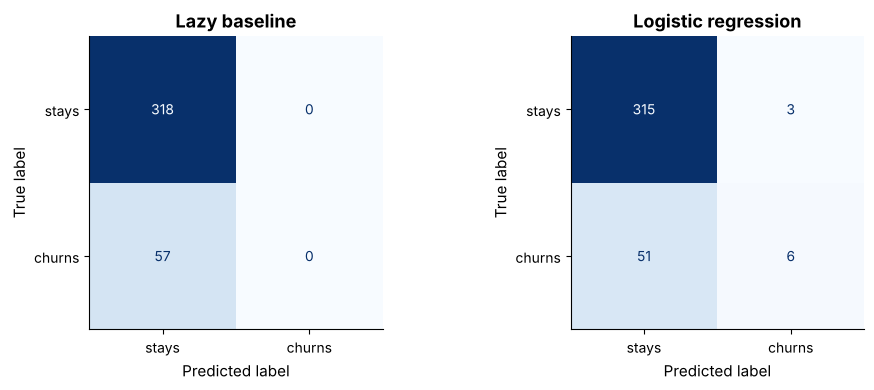

              precision    recall  f1-score   support

       stays       0.86      0.99      0.92       318
      churns       0.67      0.11      0.18        57

    accuracy                           0.86       375
   macro avg       0.76      0.55      0.55       375
weighted avg       0.83      0.86      0.81       375



In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, m) in zip(axes, {"Lazy baseline": lazy, "Logistic regression": logit}.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), display_labels=["stays", "churns"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name); ax.grid(False)
plt.tight_layout(); plt.show()
print(classification_report(y_test, pred, target_names=["stays", "churns"]))

Look closely at the two rows. **Accuracy barely moves** (84.8% → 85.6%), yet the logistic regression now catches *some* churners (recall ≈ 10%) while the lazy model catches none: a difference that is almost invisible in accuracy but obvious in recall and F1. Notice too that a recall of ~10% is still **poor**: at the default 0.5 threshold the model is far too timid, flagging only 9 customers out of 57 real churners in the test set. The next section shows how to fix that *without retraining anything*.

`classification_report` prints precision, recall and F1 **per class** (and the *support*, the number of true examples of each class). For a rare positive class, **look at the positive class's row**, not the overall accuracy.

---
# 📖 Part 4: Thresholds: you control the trade-off

Most classifiers don't output "yes/no" directly. They output a **probability** (`predict_proba`), and `predict` just applies a **threshold**: usually 0.5:

> *"If P(churn) ≥ 0.5, predict churn."*

But **0.5 is a convention, not a law.** Lower the threshold → we flag more customers → **recall ↑, precision ↓.** Raise it → fewer, more confident flags → **precision ↑, recall ↓.**

In [7]:
proba = logit.predict_proba(X_test)[:, 1]            # P(churn) for every test customer

rows = []
for t in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    flagged = (proba >= t).astype(int)
    rows.append({"threshold": t, "customers flagged": int(flagged.sum()),
                 "precision": precision_score(y_test, flagged, zero_division=0),
                 "recall": recall_score(y_test, flagged), "F1": f1_score(y_test, flagged)})
pd.DataFrame(rows).set_index("threshold").round(3)

,customers flagged,precision,recall,F1
threshold,,,,
0.05,241,0.220,0.930,0.356
0.10,186,0.280,0.912,0.428
0.20,115,0.365,0.737,0.488
0.30,66,0.485,0.561,0.520
0.40,26,0.538,0.246,0.337
0.50,9,0.667,0.105,0.182
0.60,6,0.833,0.088,0.159
0.70,0,0.000,0.000,0.000


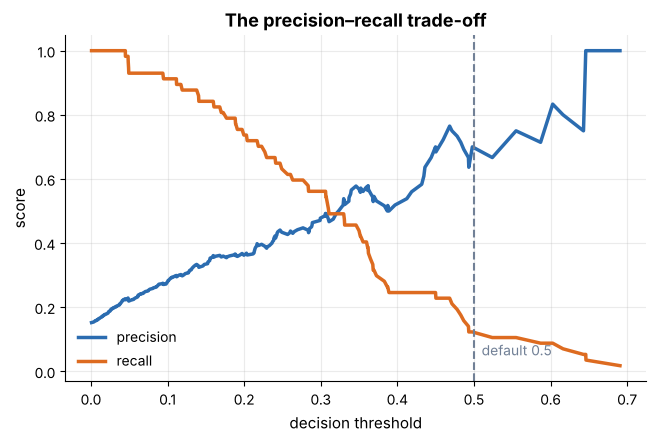

In [8]:
prec, rec, thr = precision_recall_curve(y_test, proba)
plt.plot(thr, prec[:-1], color=BLUE, lw=2.5, label="precision")
plt.plot(thr, rec[:-1], color=ORANGE, lw=2.5, label="recall")
plt.axvline(0.5, color=GREY, ls="--"); plt.text(0.51, 0.05, "default 0.5", color=GREY)
plt.xlabel("decision threshold"); plt.ylabel("score"); plt.title("The precision–recall trade-off")
plt.legend(); plt.show()

### 🧑‍🏫 Worked Example 2: Pick the threshold with *business costs*

Suppose the marketing team tells us:

* A **missed churner (FN)** costs us the customer's lifetime value: **\$500**.
* A **false alarm (FP)** costs a retention discount we didn't need to give: **\$50**.

Missing a churner is **10× worse** than a false alarm. Intuitively we should flag *liberally*. Let's compute the **total cost** at each threshold and choose the cheapest.

*Honesty rule from Lesson 4:* we choose the threshold on data that isn't the test set. Here we use **cross-validated predictions on the training set** (`cross_val_predict`) so every training customer gets a fair, out-of-fold probability.

cost at the default threshold 0.50 : $77,100
cost at the best threshold 0.09   : $31,150


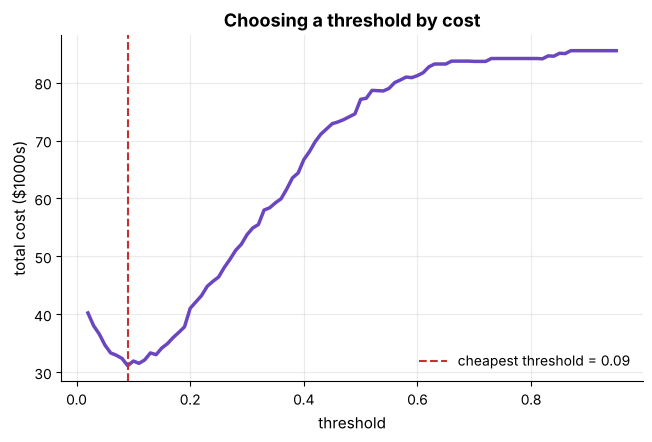

In [9]:
COST_FN, COST_FP = 500, 50
oof = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
                        X_train, y_train, cv=5, method="predict_proba")[:, 1]

grid = np.arange(0.02, 0.96, 0.01)
def total_cost(y_true, p, t):
    flagged = p >= t
    fn = ((y_true == 1) & ~flagged).sum(); fp = ((y_true == 0) & flagged).sum()
    return COST_FN * fn + COST_FP * fp

costs = np.array([total_cost(y_train.to_numpy(), oof, t) for t in grid])
best_t = grid[costs.argmin()]
print(f"cost at the default threshold 0.50 : ${total_cost(y_train.to_numpy(), oof, 0.5):,.0f}")
print(f"cost at the best threshold {best_t:.2f}   : ${costs.min():,.0f}")

plt.plot(grid, costs / 1000, color=PURPLE, lw=2.5); plt.axvline(best_t, color=RED, ls="--", label=f"cheapest threshold = {best_t:.2f}")
plt.xlabel("threshold"); plt.ylabel("total cost ($1000s)"); plt.title("Choosing a threshold by cost"); plt.legend(); plt.show()

In [10]:
flag_test = (proba >= best_t).astype(int)
print(f"On the TEST set with threshold {best_t:.2f}:  recall = {recall_score(y_test, flag_test):.2f},  precision = {precision_score(y_test, flag_test):.2f}")
print(f"Total test cost: ${total_cost(y_test.to_numpy(), proba, best_t):,.0f}   vs   ${total_cost(y_test.to_numpy(), proba, 0.5):,.0f} at the default 0.5")

On the TEST set with threshold 0.09:  recall = 0.93,  precision = 0.27
Total test cost: $9,050   vs   $25,650 at the default 0.5


The optimum sits far below 0.5. A neat rule of thumb (valid when probabilities are well calibrated): the best threshold is about

$$t^\* \approx \frac{\text{cost}_{FP}}{\text{cost}_{FP}+\text{cost}_{FN}} = \frac{50}{50+500} \approx 0.09.$$

The model didn't change: **we changed the decision rule to reflect what mistakes cost.** This is how ML meets business reality.

---
# 📖 Part 5: ROC curves and AUC: judging a model *across all thresholds*

Precision and recall depend on one chosen threshold. How do we compare *models* without committing to a threshold? Sweep the threshold from 1 down to 0 and, at each step, record:

* **TPR** (true-positive rate = recall): the share of real positives we catch.
* **FPR** (false-positive rate = 1 − specificity): the share of real negatives we *wrongly* flag.

Plotting TPR (y-axis) against FPR (x-axis) gives the **ROC curve** (*Receiver Operating Characteristic*, a name from WWII radar). A better model hugs the **top-left corner** (high TPR, low FPR). The diagonal is coin-flipping.

The **AUC** (*Area Under the Curve*) squeezes the whole curve into one number: **1.0 = perfect, 0.5 = random guessing.**

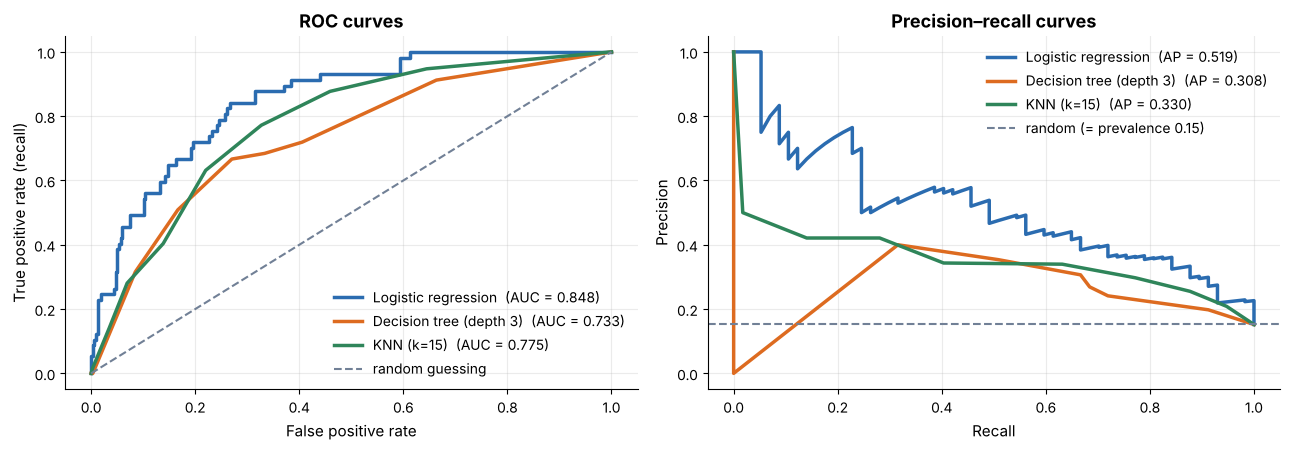

In [11]:
models = {
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision tree (depth 3)": DecisionTreeClassifier(max_depth=3, random_state=0),
    "KNN (k=15)": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for (name, m), c in zip(models.items(), [BLUE, ORANGE, GREEN]):
    m.fit(X_train, y_train)
    s = m.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, s)
    axes[0].plot(fpr, tpr, color=c, lw=2.5, label=f"{name}  (AUC = {roc_auc_score(y_test, s):.3f})")
    p_, r_, _ = precision_recall_curve(y_test, s)
    axes[1].plot(r_, p_, color=c, lw=2.5, label=f"{name}  (AP = {average_precision_score(y_test, s):.3f})")
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", label="random guessing")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)"); axes[0].set_title("ROC curves"); axes[0].legend(loc="lower right")
axes[1].axhline(y_test.mean(), color=GREY, ls="--", label=f"random (= prevalence {y_test.mean():.2f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision–recall curves"); axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

### What does AUC *mean*, concretely?

> **AUC = the probability that a randomly chosen positive example gets a higher score than a randomly chosen negative example.**

AUC = 0.80 means: *pick a random churner and a random loyal customer: 80% of the time the model gives the churner the higher churn probability.* It measures **ranking quality**, independent of any threshold.

### 🧑‍🏫 Worked Example 3: Prove it with brute force

Six customers (3 churners, 3 stayers) with model scores. I'll compare **every churner–stayer pair** (3 × 3 = 9 pairs) and count how often the churner scores higher (ties count half):

In [12]:
labels = np.array([1, 1, 1, 0, 0, 0])
scores = np.array([0.9, 0.7, 0.4, 0.8, 0.3, 0.2])

pos, neg = scores[labels == 1], scores[labels == 0]
wins = sum((p > n) + 0.5 * (p == n) for p in pos for n in neg)
print(f"pairs where the positive outranks the negative: {wins} of {len(pos) * len(neg)}")
print(f"AUC by counting pairs : {wins / (len(pos) * len(neg)):.4f}")
print(f"AUC from sklearn      : {roc_auc_score(labels, scores):.4f}")

pairs where the positive outranks the negative: 7.0 of 9
AUC by counting pairs : 0.7778
AUC from sklearn      : 0.7778


Identical. (7 of 9 pairs are ranked correctly: the churner at 0.7 loses to the stayer at 0.8, and the churner at 0.4 loses to the same one.) No integrals needed; AUC is just *pairwise ranking accuracy*.

### ROC vs. precision–recall: which one when?

| | **ROC / AUC** | **Precision–Recall / AP** |
|---|---|---|
| Good when | classes are roughly balanced; you care about both classes | the positive class is **rare** and you care mostly about it |
| Weakness | can look rosy when negatives vastly outnumber positives (FPR stays tiny) | baseline depends on prevalence (the dashed line) |
| Reading | 0.5 = random, 1.0 = perfect | random = prevalence; higher is better |

---
# 📖 Part 6: More than two classes

With three or more classes, the confusion matrix is just bigger, and precision/recall are computed **per class**. To get a single number, average them:

| Averaging | How | Use when |
|---|---|---|
| **macro** | average the per-class scores equally | every class matters equally (rare classes included) |
| **weighted** | average weighted by class frequency | you care about overall performance |
| **micro** | pool all TP/FP/FN first (for single-label tasks equals accuracy) | overall counts matter |

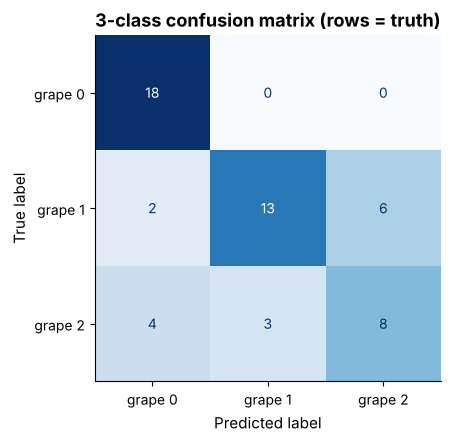

              precision    recall  f1-score   support

           0      0.750     1.000     0.857        18
           1      0.812     0.619     0.703        21
           2      0.571     0.533     0.552        15

    accuracy                          0.722        54
   macro avg      0.711     0.717     0.704        54
weighted avg      0.725     0.722     0.712        54



In [13]:
wine = load("wine.csv")
Xw, yw = wine.drop(columns="target"), wine["target"]
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.3, random_state=0, stratify=yw)
# Deliberately NO scaling here (remember Lesson 3?): KNN on raw wine data is distracted by the huge 'proline' column,
# which gives us an imperfect model, and therefore a confusion matrix worth reading.
wine_model = KNeighborsClassifier(n_neighbors=5).fit(Xw_tr, yw_tr)
wp = wine_model.predict(Xw_te)

ConfusionMatrixDisplay.from_predictions(yw_te, wp, display_labels=["grape 0", "grape 1", "grape 2"], cmap="Blues", colorbar=False)
plt.grid(False); plt.title("3-class confusion matrix (rows = truth)"); plt.show()
print(classification_report(yw_te, wp, digits=3))

Read a multiclass confusion matrix by rows: *"of all the true grape-1 wines, where did they end up?"* Here, 13 were identified correctly but **6 were mistaken for grape 2** and 2 for grape 0; grape 0 was never missed (recall 1.0) but is over-predicted (precision 0.75). The diagonal is correct; anything off-diagonal tells you **which classes get confused with which**: a goldmine for improving the model. (Put a `StandardScaler` in front and accuracy jumps from about 72% to 96%; try it!)

### 🧭 Choosing a metric: cheat sheet

| Situation | Metric to optimise / report |
|---|---|
| Balanced classes, equal costs | accuracy (+ confusion matrix) |
| Imbalanced classes | **precision, recall, F1** of the minority class; **PR-AUC** |
| Missing a positive is very costly (disease, fraud) | **recall** (at an acceptable precision) |
| False alarms are very costly (spam, legal action) | **precision** |
| Comparing models independent of threshold | **ROC-AUC** (balanced) / **PR-AUC** (rare positives) |
| Business costs known | **expected cost** at a tuned threshold |
| Always | the **baseline** and the **confusion matrix** |

---
# 🧩 Your turn: Problems

### 🧩 Problem 7.1: Count the four outcomes &nbsp; ⭐

Given the truth and predictions below (1 = positive), compute `tp`, `fp`, `fn`, `tn` **without using scikit-learn's confusion_matrix**.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Use boolean masks: `(y_true == 1) & (y_pred == 1)` is `True` exactly for true positives. `.sum()` counts them.

</details>

In [ ]:
y_true = np.array([1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1])
y_pred = np.array([1, 0, 0, 1, 1, 0, 1, 0, 0, 0, 0, 1])

tp = fp = fn = tn = None
print(tp, fp, fn, tn)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("TP = 4", lambda: tp == 4)
check("FP = 1", lambda: fp == 1)
check("FN = 2", lambda: fn == 2)
check("TN = 5", lambda: tn == 5)

### 🧩 Problem 7.2: From counts to metrics &nbsp; ⭐

Using the counts from the previous problem (given again below), compute: `accuracy`, `precision`, `recall`, `specificity`, `f1`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`precision = tp / (tp + fp)`, `recall = tp / (tp + fn)`, `specificity = tn / (tn + fp)`.

</details>

<details>
<summary>💡 Hint 2</summary>

`f1 = 2 * precision * recall / (precision + recall)`.

</details>

In [ ]:
tp, fp, fn, tn = 4, 1, 2, 5

accuracy = precision = recall = specificity = f1 = None
print(accuracy, precision, recall, specificity, f1)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("accuracy = 0.75", lambda: abs(accuracy - 0.75) < 1e-9)
check("precision = 0.8", lambda: abs(precision - 0.8) < 1e-9)
check("recall = 2/3", lambda: abs(recall - 2 / 3) < 1e-9)
check("specificity = 5/6", lambda: abs(specificity - 5 / 6) < 1e-9)
check("F1 ≈ 0.727", lambda: abs(f1 - 0.72727) < 1e-4)

### 🧩 Problem 7.3: Beat the accuracy paradox &nbsp; ⭐⭐

Using the churn split provided (`X_train, X_test, y_train, y_test`):

1. Train `DummyClassifier(strategy="most_frequent")` → store test accuracy in `dummy_acc` and test recall in `dummy_recall`.
2. Train `make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))` → store its test `lr_acc`, `lr_recall`, `lr_f1`.
3. Store `True` or `False` in `accuracy_misleads`: *"does the dummy model have higher accuracy than **or equal to within 5 points** of the logistic model while having zero recall?"* (i.e. `dummy_acc >= lr_acc - 0.05 and dummy_recall == 0`).

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`recall_score(y_test, model.predict(X_test))`.

</details>

<details>
<summary>💡 Hint 2</summary>

Compute the boolean exactly as the sentence says.

</details>

In [ ]:
churn = load("churn.csv")
X, y = churn.drop(columns="churned"), churn["churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

dummy_acc = dummy_recall = lr_acc = lr_recall = lr_f1 = None
accuracy_misleads = None
print(dummy_acc, dummy_recall, lr_acc, lr_recall, lr_f1, accuracy_misleads)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("dummy accuracy is above 80%", lambda: dummy_acc > 0.80)
check("dummy recall is exactly 0", lambda: dummy_recall == 0)
check("logistic regression finds some churners (recall > 0)", lambda: lr_recall > 0)
check("F1 is much lower than accuracy for the logistic model (imbalance bites)", lambda: lr_f1 < lr_acc - 0.2)
check("accuracy_misleads is True", lambda: accuracy_misleads is True)

### 🧩 Problem 7.4: Find the threshold for 80% recall &nbsp; ⭐⭐

The business needs to **catch at least 80% of churners**. Use the split and model provided (train / validation / test; probabilities for validation and test are already computed).

1. Over thresholds `np.arange(0.02, 0.96, 0.01)`, find the **largest** threshold whose **validation recall is ≥ 0.80** (a larger threshold flags fewer customers, so it gives the best precision). Store it in `best_threshold`.
2. Store the validation precision and recall at that threshold in `val_precision` and `val_recall`.
3. Apply the *same* threshold to the **test** probabilities and store `test_recall`, `test_precision`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Loop over thresholds, compute `flagged = (p_val >= t).astype(int)`, and `recall_score(y_val, flagged)`. Keep the largest `t` that satisfies the condition.

</details>

<details>
<summary>💡 Hint 2</summary>

Never choose the threshold on `p_test`: that's the whole point of having a validation set.

</details>

In [ ]:
churn = load("churn.csv")
X, y = churn.drop(columns="churned"), churn["churned"]
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=0, stratify=y_rest)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
p_val, p_test = model.predict_proba(X_val)[:, 1], model.predict_proba(X_test)[:, 1]
thresholds = np.arange(0.02, 0.96, 0.01)

best_threshold = val_precision = val_recall = test_recall = test_precision = None
print(best_threshold, val_recall, test_recall)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_ok = [t for t in thresholds if recall_score(y_val, (p_val >= t).astype(int)) >= 0.80]
check("best_threshold is the largest one with validation recall ≥ 0.80", lambda: abs(best_threshold - max(_ok)) < 1e-9)
check("validation recall ≥ 0.80", lambda: val_recall >= 0.80)
check("test recall is in the same region (> 0.65)", lambda: test_recall > 0.65)
check("precision is modest (the price of high recall): < 0.5", lambda: val_precision < 0.5)

### 🧩 Problem 7.5: AUC by counting pairs &nbsp; ⭐⭐

Implement `auc_by_pairs(labels, scores)`: for every (positive, negative) pair count `1` if the positive's score is higher, `0.5` if tied, `0` otherwise, and return the **average**.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Split scores into `pos = scores[labels == 1]` and `neg = scores[labels == 0]`.

</details>

<details>
<summary>💡 Hint 2</summary>

`np.mean([(p > n) + 0.5 * (p == n) for p in pos for n in neg])` does the job.

</details>

In [ ]:
def auc_by_pairs(labels, scores):
    return None

In [ ]:
# ✔ Self-check - run this after you have solved the problem
_rng = np.random.default_rng(0)
_labels = _rng.integers(0, 2, 200); _scores = _rng.normal(size=200) + _labels
check("matches roc_auc_score on 200 random points", lambda: abs(auc_by_pairs(_labels, _scores) - roc_auc_score(_labels, _scores)) < 1e-9)
check("handles ties (AUC of constant scores = 0.5)", lambda: abs(auc_by_pairs(np.array([0, 1, 0, 1]), np.array([.5, .5, .5, .5])) - 0.5) < 1e-9)

### 🧩 Problem 7.6: Pick the best model by AUC &nbsp; ⭐⭐

Using the churn split provided, train these three models and compute each one's **test ROC-AUC** (from `predict_proba(...)[:, 1]`). Store in a dictionary `aucs` keyed `"logistic"`, `"tree"`, `"knn"`, and store the winner's key in `best_name`.

* `"logistic"` → `make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))`
* `"tree"` → `DecisionTreeClassifier(max_depth=3, random_state=0)`
* `"knn"` → `make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))`

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

Put the three models in a dictionary, loop, `fit` on the training data, and score with `roc_auc_score(y_test, model.predict_proba(X_test)[:, 1])`.

</details>

In [ ]:
churn = load("churn.csv")
X, y = churn.drop(columns="churned"), churn["churned"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)

aucs = {}
best_name = None
print(aucs, best_name)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("three AUCs recorded", lambda: sorted(aucs) == ["knn", "logistic", "tree"])
check("all better than random (> 0.5)", lambda: all(v > 0.5 for v in aucs.values()))
check("best_name is the model with the highest AUC", lambda: best_name == max(aucs, key=aucs.get))
check("logistic regression ranks well (AUC > 0.8)", lambda: aucs["logistic"] > 0.8)

### 🧩 Problem 7.7: Cost-sensitive threshold &nbsp; ⭐⭐⭐

A missed churner costs **\$500**; a false alarm costs **\$50**. With the validation probabilities provided:

1. Write `cost(y_true, p, t)` returning the total cost when flagging customers with `p >= t`.
2. Search `np.arange(0.02, 0.96, 0.01)` for the threshold minimising the **validation** cost → `best_t`.
3. Store the validation cost at `best_t` in `cost_best` and at the default 0.5 in `cost_default`.

**Stuck?** Open the hints one at a time: try again between each one.

<details>
<summary>💡 Hint 1</summary>

`fn = ((y_true == 1) & (p < t)).sum()` and `fp = ((y_true == 0) & (p >= t)).sum()`; cost = `500*fn + 50*fp`.

</details>

<details>
<summary>💡 Hint 2</summary>

Compute the cost for each threshold in a list and take `thresholds[np.argmin(costs)]`.

</details>

In [ ]:
churn = load("churn.csv")
X, y = churn.drop(columns="churned"), churn["churned"]
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_rest, y_rest, test_size=0.25, random_state=0, stratify=y_rest)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
p_val = model.predict_proba(X_val)[:, 1]
thresholds = np.arange(0.02, 0.96, 0.01)

def cost(y_true, p, t):
    return None

best_t = cost_best = cost_default = None
print(best_t, cost_best, cost_default)

In [ ]:
# ✔ Self-check - run this after you have solved the problem
check("cost function works on a tiny example (1 FN + 1 FP = 550)", lambda: cost(np.array([1, 0]), np.array([0.2, 0.9]), 0.5) == 550)
check("cost_default is the cost at t = 0.5", lambda: cost_default == cost(y_val.to_numpy(), p_val, 0.5))
check("best_t is cheaper than the default", lambda: cost_best < cost_default)
check("best_t is well below 0.5 (misses cost 10× more)", lambda: best_t < 0.3)

---
## 🎟️ Exit ticket

**Q1.** A fraud model on 10,000 transactions (30 fraudulent) has 99.7% accuracy. Is it good?
**Q2.** Define precision and recall in one sentence each, using the smoke-alarm analogy.
**Q3.** You lower the threshold from 0.5 to 0.2. What happens to recall and precision (typically)?
**Q4.** What does AUC = 0.5 mean? What does AUC = 0.9 mean?
**Q5.** A spam filter vs a cancer screen: which would you tune for precision, which for recall?

<details><summary>👀 Answers</summary>

**A1.** Not necessarily: "never flag fraud" already scores 99.7% (9,970/10,000). Look at recall, precision and the confusion matrix.
**A2.** Precision: when the alarm rings, how often is there really a fire? Recall: of all real fires, what fraction rang the alarm?
**A3.** Recall rises (or stays equal); precision usually falls: more flags, more false alarms.
**A4.** 0.5 = no ranking ability (coin flip). 0.9 = a random positive is scored above a random negative 90% of the time.
**A5.** Spam → precision (don't lose real mail). Cancer screen → recall (don't miss a case).

</details>

---
## 📌 Recap: Lesson 7 on one page

* **Accuracy** misleads when classes are imbalanced (the **accuracy paradox**). Always compare with a majority-class baseline.
* **Confusion matrix** `[[TN, FP], [FN, TP]]`. **Precision** = TP/(TP+FP). **Recall** = TP/(TP+FN). **Specificity** = TN/(TN+FP). **F1** = harmonic mean of P and R.
* **Threshold** is a dial: lower → recall ↑ precision ↓. Choose it from **costs** (≈ cost_FP / (cost_FP + cost_FN)), on **validation/CV** data, never on the test set.
* **ROC curve** (TPR vs FPR) and **AUC** = probability a random positive outranks a random negative. For rare positives, prefer **precision–recall / AP**.
* Multiclass: per-class metrics + **macro / weighted / micro** averages; read the confusion matrix row by row.
* **The metric must encode what mistakes cost.**

**Next up →** `08_optimization.ipynb`: we've evaluated models; now let's open the hood and see *how they learn*: loss functions and gradient descent.